<a href="https://colab.research.google.com/github/joobnsucky/MyAI/blob/main/%EC%8B%A4%EC%8A%B5%EA%B2%B0%EA%B3%BC%EC%A0%95%EB%A6%AC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 실습 결과 정리 — 단독 실행 버전

이 파일만 열고 **런타임 → 모두 실행**을 선택하세요. 다른 노트북을 먼저 실행하거나 복사할 필요가 없습니다.

- 원본 실습과 동일한 말뭉치, 난수 시드(42), 모델 및 IMDb 데이터 분할을 사용합니다.
- Skip-gram은 window=1/3 각각 35 epochs, 리뷰 분류는 두 모델 각각 4 epochs를 새로 학습합니다.
- Colab CPU에서도 실행할 수 있습니다. 첫 실행에는 IMDb 다운로드를 위한 인터넷과 학습 시간이 필요합니다.
- 정확도와 이웃 단어는 실행 환경에 따라 달라질 수 있으며, 아래 출력은 이번 실행에서 계산됩니다.

## 0. 공통 라이브러리와 실행 설정


In [2]:
# 로컬 Jupyter에서 아래 라이브러리가 없다면 다음 줄의 주석을 풀어 실행하세요.
# %pip install tensorflow matplotlib

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
keras.utils.set_random_seed(SEED)
print("TensorFlow:", tf.__version__)


def make_dataset(x, y, batch_size, shuffle=False):
    dataset = tf.data.Dataset.from_tensor_slices((x, y))
    if shuffle:
        dataset = dataset.shuffle(len(y), seed=SEED)
    options = tf.data.Options()
    options.threading.private_threadpool_size = 2
    return dataset.batch(batch_size).with_options(options)

TensorFlow: 2.21.0


#### 1. Smoothing 적용 전후에 미관측 bigram의 확률을 비교하세요.

In [3]:
from collections import Counter

sentences = [
    "i like this movie", "i like this story", "i like this film",
    "i love this movie", "we love this film", "we like the story",
    "this movie is good", "this story is good", "this film is great",
    "i dislike this movie", "i dislike this film", "we dislike the story",
    "this movie is boring", "this film is boring", "the story is bad",
]
tokenized = [sentence.split() for sentence in sentences]
word_counts = Counter(word for sentence in tokenized for word in sentence)
print("전체 토큰 수:", sum(word_counts.values()))
print("고유 단어 수:", len(word_counts))
print("빈도가 높은 단어:", word_counts.most_common(6))

# <s>는 입력 문맥에만 사용하고, </s>는 예측 가능한 토큰에 포함합니다.
unigram_counts = word_counts.copy()
unigram_counts["</s>"] = len(tokenized)
vocabulary = sorted(unigram_counts)

bigram_counts = {}
for words in tokenized:
    sequence = ["<s>"] + words + ["</s>"]
    for previous, current in zip(sequence, sequence[1:]):
        bigram_counts.setdefault(previous, Counter())[current] += 1

print("like 뒤에 등장한 단어:", bigram_counts["like"])

전체 토큰 수: 60
고유 단어 수: 15
빈도가 높은 단어: [('this', 12), ('i', 6), ('is', 6), ('movie', 5), ('story', 5), ('film', 5)]
like 뒤에 등장한 단어: Counter({'this': 3, 'the': 1})


In [4]:
def next_word_probs(previous=None, alpha=0.0):
    counts = unigram_counts if previous is None else bigram_counts.get(previous, Counter())
    weights = np.array([counts[word] + alpha for word in vocabulary], dtype=float)
    if weights.sum() == 0:
        raise ValueError("이 문맥은 미관측 문맥입니다. alpha를 양수로 설정하세요.")
    return weights / weights.sum()


def top_next_words(previous=None, alpha=0.0, k=5):
    probs = next_word_probs(previous, alpha)
    indices = np.argsort(-probs, kind="stable")[:k]
    return [(vocabulary[i], round(float(probs[i]), 3)) for i in indices]




In [5]:
context = "like"
probe_word = "good" # 실습 말뭉치에서 'like good'이라는 순서로 등장한 적이 없음을 가정합니다.

prob_before = next_word_probs(context, alpha=0.0)[vocabulary.index(probe_word)]
prob_after = next_word_probs(context, alpha=0.1)[vocabulary.index(probe_word)]

print(f"Smoothing 전 (alpha=0.0) P({probe_word} | {context}) = {prob_before:.4f}")
print(f"Smoothing 후 (alpha=0.1) P({probe_word} | {context}) = {prob_after:.4f}")

Smoothing 전 (alpha=0.0) P(good | like) = 0.0000
Smoothing 후 (alpha=0.1) P(good | like) = 0.0179


**답변:**
Smoothing을 적용하기 전(`alpha=0.0`)에는 말뭉치에 한 번도 등장하지 않은 미관측 문맥 조합(`like` 뒤에 `good`이 오는 경우)의 확률이 0으로 계산됩니다. 하지만 Add-alpha Smoothing을 적용한 후(`alpha=0.1`)에는 0이 아닌 양의 확률을 부여받게 되어, 한 번도 보지 못한 문장 조합이 등장했을 때 전체 문장 확률이 0이 되어버리는 희소성(Sparsity) 문제를 방지할 수 있습니다.

#### 2. Skip-gram에서 window 크기 두 가지를 사용해 동일 단어의 상위 이웃을 비교하세요.

In [6]:
# 같은 종류의 단어가 비슷한 문맥에 나타나는 작은 예제입니다.
word_groups = [
    (["cat", "dog", "rabbit"], ["is a friendly pet", "eats food at home", "likes to play"]),
    (["apple", "pear", "peach"], ["is a sweet fruit", "grows on a tree", "tastes fresh"]),
    (["car", "bus", "truck"], ["drives on the road", "stops at a light", "has four wheels"]),
]

corpus = [
    f"the {word} {context}".split()
    for words, contexts in word_groups
    for word in words
    for context in contexts
]
words = sorted({word for sentence in corpus for word in sentence})
word_to_id = {word: index for index, word in enumerate(words)}
print("예시 문장:", corpus[:3])
print("어휘 크기:", len(words))


def skipgram_pairs(sentences, window):
    centers, contexts = [], []
    for sentence in sentences:
        ids = [word_to_id[word] for word in sentence]
        for center_pos, center_id in enumerate(ids):
            left = max(0, center_pos - window)
            right = min(len(ids), center_pos + window + 1)
            for context_pos in range(left, right):
                if context_pos != center_pos:
                    centers.append(center_id)
                    contexts.append(ids[context_pos])
    return np.array(centers, dtype="int32"), np.array(contexts, dtype="int32")




예시 문장: [['the', 'cat', 'is', 'a', 'friendly', 'pet'], ['the', 'cat', 'eats', 'food', 'at', 'home'], ['the', 'cat', 'likes', 'to', 'play']]
어휘 크기: 35


In [7]:
def train_skipgram(window, embedding_dim=12, epochs=35):
    keras.utils.set_random_seed(SEED)
    centers, contexts = skipgram_pairs(corpus, window)

    model = keras.Sequential([
        keras.Input(shape=(), dtype="int32"),
        layers.Embedding(len(words), embedding_dim, name="word_vectors"),
        layers.Dense(len(words), use_bias=False),
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.03),
        loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    )
    dataset = make_dataset(centers, contexts, batch_size=64, shuffle=True)
    history = model.fit(dataset, epochs=epochs, shuffle=False, verbose=0)
    vectors = model.get_layer("word_vectors").get_weights()[0]
    return vectors, history


def similar_words(word, vectors, k=5):
    index = word_to_id[word]
    norms = np.linalg.norm(vectors, axis=1, keepdims=True)
    normalized = vectors / np.maximum(norms, 1e-12)
    similarities = normalized @ normalized[index]
    order = [i for i in np.argsort(-similarities) if i != index]
    return [(words[i], round(float(similarities[i]), 3)) for i in order[:k]]




In [8]:
query_word = "cat"

# window=1과 window=3에서의 학습 결과를 비교합니다.
my_vectors_w1, _ = train_skipgram(window=1)
my_vectors_w3, _ = train_skipgram(window=3)

print(f"window=1 | {query_word} ->", similar_words(query_word, my_vectors_w1))
print(f"window=3 | {query_word} ->", similar_words(query_word, my_vectors_w3))

window=1 | cat -> [('rabbit', 1.0), ('dog', 0.999), ('road', 0.693), ('pear', 0.603), ('peach', 0.595)]
window=3 | cat -> [('rabbit', 1.0), ('dog', 0.999), ('pet', 0.685), ('home', 0.654), ('to', 0.483)]


**해석:** window=1은 바로 인접한 단어를, window=3은 좌우 최대 세 단어를 학습 대상으로 사용합니다. 출력된 이웃과 유사도를 비교하세요. 작은 예제 말뭉치이므로 window를 늘리면 의미적 유사성이 반드시 좋아진다고 단정할 수 없습니다.


#### 3. 리뷰 분류 모델의 검증 정확도와 파라미터 수를 비교하고, 결과를 한 문장으로 해석하세요.

In [9]:
from tensorflow.keras.datasets import imdb
from tensorflow.keras.utils import pad_sequences

max_features = 5000
maxlen = 80

# 수업에서 빠르게 비교할 수 있도록 원본 데이터의 일부를 사용합니다.
(train_reviews, train_labels), (test_reviews, test_labels) = imdb.load_data(
    num_words=max_features, seed=SEED
)

x_train = pad_sequences(train_reviews[:5000], maxlen=maxlen, padding="post", truncating="post")
x_val = pad_sequences(train_reviews[5000:6000], maxlen=maxlen, padding="post", truncating="post")
x_test = pad_sequences(test_reviews[:1500], maxlen=maxlen, padding="post", truncating="post")
y_train, y_val, y_test = train_labels[:5000], train_labels[5000:6000], test_labels[:1500]

for name, x, y in [("train", x_train, y_train), ("val", x_val, y_val), ("test", x_test, y_test)]:
    print(f"{name:5s} | 입력 {x.shape} | 긍정 리뷰 비율 {y.mean():.1%}")

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
train | 입력 (5000, 80) | 긍정 리뷰 비율 50.3%
val   | 입력 (1000, 80) | 긍정 리뷰 비율 47.7%
test  | 입력 (1500, 80) | 긍정 리뷰 비율 48.9%


In [10]:
def build_sentiment_model(use_rnn, units=32):
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([
        keras.Input(shape=(maxlen,), dtype="int32"),
        layers.Embedding(max_features, 32, mask_zero=True),
    ])
    if use_rnn:
        # 학습 초기에 직전 상태가 다음 시점으로 전달되도록 0.95 × I에서 시작합니다.
        model.add(layers.SimpleRNN(
            units, recurrent_initializer=keras.initializers.Identity(gain=0.95)
        ))
    else:
        model.add(layers.GlobalAveragePooling1D())
    model.add(layers.Dense(1, activation="sigmoid"))
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return model


def sentiment_train_dataset():
    return make_dataset(x_train, y_train, batch_size=128, shuffle=True)


val_ds = make_dataset(x_val, y_val, batch_size=128)
test_ds = make_dataset(x_test, y_test, batch_size=128)

histories = {}
model_params = {}
test_accuracies = {}
for name, use_rnn in [("Embedding + Mean", False), ("Embedding + SimpleRNN", True)]:
    model = build_sentiment_model(use_rnn)
    print(f"학습 시작: {name}")
    histories[name] = model.fit(
        sentiment_train_dataset(), validation_data=val_ds, epochs=4, shuffle=False, verbose=2,
    )
    _, test_acc = model.evaluate(test_ds, verbose=0)
    model_params[name] = model.count_params()
    test_accuracies[name] = float(test_acc)
    print(f"{name:25s} | parameters={model.count_params():,} | test accuracy={test_acc:.1%}")

학습 시작: Embedding + Mean
Epoch 1/4
40/40 - 1s - 32ms/step - accuracy: 0.5320 - loss: 0.6898 - val_accuracy: 0.5940 - val_loss: 0.6858
Epoch 2/4
40/40 - 0s - 8ms/step - accuracy: 0.6532 - loss: 0.6789 - val_accuracy: 0.6570 - val_loss: 0.6750
Epoch 3/4
40/40 - 1s - 15ms/step - accuracy: 0.7052 - loss: 0.6639 - val_accuracy: 0.6790 - val_loss: 0.6610
Epoch 4/4
40/40 - 0s - 8ms/step - accuracy: 0.7192 - loss: 0.6451 - val_accuracy: 0.6970 - val_loss: 0.6443
Embedding + Mean          | parameters=160,033 | test accuracy=70.9%
학습 시작: Embedding + SimpleRNN
Epoch 1/4
40/40 - 4s - 99ms/step - accuracy: 0.6784 - loss: 0.5905 - val_accuracy: 0.7500 - val_loss: 0.5237
Epoch 2/4
40/40 - 2s - 43ms/step - accuracy: 0.8468 - loss: 0.3810 - val_accuracy: 0.7560 - val_loss: 0.5089
Epoch 3/4
40/40 - 3s - 64ms/step - accuracy: 0.8782 - loss: 0.3195 - val_accuracy: 0.7480 - val_loss: 0.5931
Epoch 4/4
40/40 - 1s - 33ms/step - accuracy: 0.9102 - loss: 0.2498 - val_accuracy: 0.7640 - val_loss: 0.6205
Embeddin

In [11]:
# 이번 노트북에서 실제로 학습한 모델의 파라미터 수와 마지막 검증 정확도
for name, history in histories.items():
    val_acc = history.history['val_accuracy'][-1]
    print(f"{name:25s} | 파라미터 수={model_params[name]:,} | 마지막 검증 정확도={val_acc:.1%}")

mean_name, rnn_name = 'Embedding + Mean', 'Embedding + SimpleRNN'
mean_acc = histories[mean_name].history['val_accuracy'][-1]
rnn_acc = histories[rnn_name].history['val_accuracy'][-1]
extra = model_params[rnn_name] - model_params[mean_name]
if rnn_acc > mean_acc:
    comparison = f'SimpleRNN의 검증 정확도가 {(rnn_acc-mean_acc)*100:.2f}%p 높았습니다'
elif rnn_acc < mean_acc:
    comparison = f'Mean의 검증 정확도가 {(mean_acc-rnn_acc)*100:.2f}%p 높았습니다'
else:
    comparison = '두 모델의 검증 정확도가 같았습니다'
print(f"\n한 문장 해석: 이 실행에서 SimpleRNN은 Mean보다 파라미터가 {extra:,}개 더 많았으며, {comparison}.")


Embedding + Mean          | 파라미터 수=160,033 | 마지막 검증 정확도=69.7%
Embedding + SimpleRNN     | 파라미터 수=162,113 | 마지막 검증 정확도=76.4%

한 문장 해석: 이 실행에서 SimpleRNN은 Mean보다 파라미터가 2,080개 더 많았으며, SimpleRNN의 검증 정확도가 6.70%p 높았습니다.


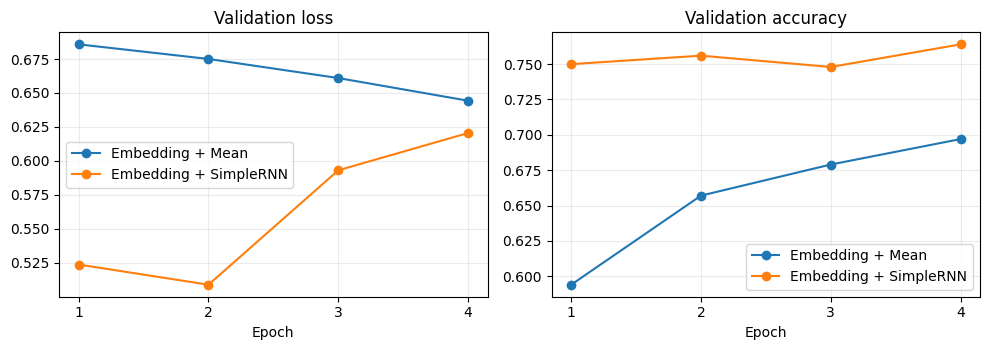

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for name, history in histories.items():
    epochs = np.arange(1, len(history.history["loss"]) + 1)
    axes[0].plot(epochs, history.history["val_loss"], marker="o", label=name)
    axes[1].plot(epochs, history.history["val_accuracy"], marker="o", label=name)
for ax, title in zip(axes, ["Validation loss", "Validation accuracy"]):
    ax.set(title=title, xlabel="Epoch", xticks=epochs)
    ax.legend()
    ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

**해석 시 주의:** 위 문장은 이번 실행의 마지막 epoch 검증 정확도에 근거합니다. 두 모델은 모두 160,000개의 임베딩 파라미터를 포함하므로 전체 파라미터 수 차이는 작습니다(Mean 160,033개, SimpleRNN 162,113개). 단일 실행만으로 어순의 중요성이나 어느 모델의 일반적인 우수성을 확정할 수 없습니다.
